In [1]:
import numpy as np
import pynbody as pnb
import os
import h5py
from pynbody.analysis.profile import Profile, VerticalProfile, InclinedProfile, QuantileProfile
import argparse
import dill
import caesar
import yt
import astropy.constants as astroc

m_p = astroc.m_p.cgs.value # mass of proton in cgs units
k_B = astroc.k_B.cgs.value # Boltzmann constant in cgs units
from astro_constants import NA_no_units, NA, kB_no_units, kB, mH, mp_no_units, mu_e, mu, G_no_units, G

profile_types = {
    'Profile':Profile,
    'VerticalProfile':VerticalProfile,
    'InclinedProfile':InclinedProfile,
    'QuantileProfile':QuantileProfile,
}

code = 'Simba-C'
name = 'entropy_prof_L1_zoom_252_644' # for output file name
#snap_file = args.snap
#output_file = args.output_filepath + '_temp_cut='+args.temp_cut+'_nh_cut='+args.nh_cut+'.pkl'
output_filename = name + '_temp_cut=5e5K_nh_cut=0.13_cm-3.pkl'
profile_type = profile_types['Profile']
weight_by = 'mass'

# define args
snap_file = '/scratch/b/babul/aspadawe/snapshots/Hyenasc_L1_zooms/halo_612/snap_halo_612_151.hdf5'
output_path = '/home/b/babul/stlock/entropy_profiles/outputs/'
temp_cut = '5e5 K' # default for now
nh_cut = '0.13 cm**-3' # default for now

print()
print('Reading in simulation snapshot')
s = pnb.load(snap_file)
s.physical_units()
print('done')
print()


Reading in simulation snapshot


/home/b/babul/stlock/.virtualenvs/entropy_venv_12/lib/python3.11/site-packages/pynbody/snapshot/gadgethdf.py:555: RuntimeWarning: No unit information found in GadgetHDF file. Using gadget default units.
  warnings.warn("No unit information found in GadgetHDF file. Using gadget default units.", RuntimeWarning)


done



# Functions

In [1]:
#useful functions, XIGrM, dill, etc

def save_object_with_dill(obj, filename):
    with open(filename, 'wb') as f:  # Overwrites any existing file.
        dill.dump(obj, f, dill.HIGHEST_PROTOCOL)

# XIGrM Functions
def nh(sim):
    '''
    Calculating hydrogen number density from density.
    '''
    #X_H = 1-sim.gas['metals'][:,0]-sim.gas['metals'][:,1] #0 for metal and 1 for He
    result = sim.gas['rho'].in_units('g cm**-3').view(np.ndarray)/m_p*sim.gas['X_H']
    result = pnb.array.SimArray(result)
    result.units = 'cm**-3'
    return result


def temp(sim):
    '''
    Convert internal energy to temperature, following 
    the instructions from `GIZMO documentation <http://www.tapir.caltech.edu/~phopkins/Site/GIZMO_files/gizmo_documentation.html#snaps>`_
    '''
    #XH = 1-sim.gas['metals'][:,0]-sim.gas['metals'][:,1]
    GAMMA = 5.0/3
    # If ne = 0 gas is unionized
    mu = 4.0 / (3.0 * sim.gas['X_H'] + 4.0 * sim.gas['X_H'] * sim.gas['ElectronAbundance'] + 1.0)
    # mu = 0.6
    result = pnb.array.SimArray(sim.gas['u'].in_units('cm**2 s**-2').view(np.ndarray) * (GAMMA - 1) * mu * (m_p / k_B))
    result.units = 'K'
    return result

@Profile.profile_property
def Ne(self):
    with self.sim.immediate_mode:
        pvol_ = self.sim['volume'].in_units('cm**3')
        pvol = pvol_.view(np.ndarray)
        pne_ = self.sim['ne'].in_units('cm**-3')
        pne = pne_.view(np.ndarray)
    
    Ne_ = pnb.array.SimArray(np.zeros(self.nbins), units=pvol_.units * pne_.units)
    for i in range(self.nbins):
        if len(self.binind[i]) == 0:
            Ne_[i] = 0
        else:
            Ne_[i] = np.nansum(pvol[self.binind[i]] * pne[self.binind[i]], axis=0)#.sum()
    return Ne_


@Profile.profile_property
def volume(self):
    return self._binsize

@Profile.profile_property # call as something like result['y'][prop + '_' + weight] = prop_weighted_avg(pg, prop, weight)
def prop_weighted_avg(self, prop, weight):
    with self.sim.immediate_mode:
        pprop_ = self.sim[prop]
        pprop = pprop_.view(np.ndarray)
        pweight_ = self.sim[weight]
        pweight = pweight_.view(np.ndarray)

    result = pnb.array.SimArray(np.zeros((self.nbins,) + pprop.shape[1:]), units=pprop_.units)
    for i in range(self.nbins):
        if len(self.binind[i]) == 0:
            result[i] = np.nan
        else:
            result[i] = np.average(pprop[self.binind[i]], weights=pweight[self.binind[i]], axis=0)
    return result


NameError: name 'Profile' is not defined

In [ ]:
# caesar halo finding
# we are getting the halo ID from the snapshots, so we need to use that to ID the halo!
obj = caesar.load('/scratch/b/babul/aspadawe/snapshots/Hyenasc_L1_zooms/halo_612/Groups/Caesar_halo_612_151.hdf5')
halo_data = obj.halos

gas_positions = s.gas['pos'] # get positions of all gas particles in box

"""
# Find min and max x, y, z for all gas particles. half them to make a rough centerpoint
min_x, min_y, min_z = np.min(gas_positions, axis=0)
max_x, max_y, max_z = np.max(gas_positions, axis=0)
half_x, half_y, half_z = (min_x+max_x)/2, (min_y+max_y)/2, (min_z+max_z)/2
length_x, length_y, length_z = np.abs(max_x-min_x)/2, np.abs(max_y-min_y)/2, np.abs(max_z-min_z)/2

# Find all halos that have a centerpoint within 1mpc from the rough centerpoint

center_arr = np.array([halo.minpotpos for halo in halo_data]) # array of all halo centers from halo_data
m500c_arr = np.array([halo.virial_quantities['m500c'] for halo in halo_data]) # array of all halo masses from halo_data
r500c_arr = np.array([halo.virial_quantities['r500c'] for halo in halo_data])
center_arr_x = center_arr[:, 0]  # Get all rows, first column (x-coordinates)
center_arr_y = center_arr[:, 1]  # second column (y-coords)
center_arr_z = center_arr[:, 2]  # third column (z-coords)

rad_array = ((center_arr_x - half_x)**2 + (center_arr_y - half_y)**2 + (center_arr_z - half_z)**2 )**(0.5)
radial_cut_ids = np.where(rad_array <= max(length_x, length_y, length_z))

m500c_arr_radial_cut = m500c_arr[radial_cut_ids]
target_mass = np.argmax(m500c_arr)
target_id = radial_cut_ids[target_mass]
# target_id = id_arr[target_idx]
target_center = center_arr[target_id]
r500 = r500c_arr[target_id]


# -----------------------------------------------------------------------------------------

massive = halo_data[0].virial_quantities['m500c']
target_halo = halo_data[0]
for halo in halo_data: # find most massive halo
    if halo.virial_quantities['m500c'] > massive:
        target_halo = halo

# get the center of that halo!
center = target_halo.minpotpos
print(f"Original center (before conversion): {center}")

center = pnb.array.SimArray(center/1000, units='kpc')
print(f"Updated center (after conversion): {center}")
r500 = target_halo.virial_quantities['r500c']

# convert to kpc

print(center)
print(r500)"
""""


yt : [INFO     ] 2025-03-20 13:15:07,403 Opening /scratch/b/babul/aspadawe/snapshots/Hyenasc_L1_zooms/halo_612/Groups/Caesar_halo_612_151.hdf5


yt : [INFO     ] 2025-03-20 13:15:07,684 Found 14894 halos
yt : [INFO     ] 2025-03-20 13:15:07,697 Found 1636 galaxies
/home/b/babul/stlock/.virtualenvs/entropy_venv_12/lib/python3.11/site-packages/pynbody/snapshot/gadgethdf.py:394: UserWarning: Unable to infer units from HDF attributes
  warnings.warn("Unable to infer units from HDF attributes")


Original center (before conversion): [122618.414 151001.66  150950.94 ] kpccm
Updated center (after conversion): [122.618416 151.00166  150.95094 ]
[122.618416 151.00166  150.95094 ]
945.2213134765625 kpccm


# YT Halo Finding

In [ ]:
snap = yt.load(snap_file)

data = snap.all_data()

def gas_entropy(field, data):
    return data["gas", "kT"] * data["gas", "El_number_density"] ** (-2.0/3.0)

def gas_entropy2(field, data):
    return data["gas", "kT"] * data["PartType0", "El_number_density"] ** (-2.0/3.0)

snap.add_field(
    ("gas", "gas_entropy"),
    units="keV*cm**2",
    function=gas_entropy,
    sampling_type="cell",
)

snap.add_field(
    ("PartType0", "gas_entropy"),
    units="keV*cm**2",
    function=gas_entropy2,
    sampling_type="particle",
    force_override=True
)

gas_entropy = data['gas', 'entropy']

#### Get Position of Highest Gas Density

In [ ]:
rho_max_index = np.argmax(data['gas', 'density'])

rho_max_pos = data['gas', 'position'][rho_max_index]
rho_max_pos.in_units('Mpc')

rho_max_part_pos = data['gas', 'particle_position'][rho_max_index]
rho_max_part_pos.in_units('Mpc')

#### Isolate IGrM and a couple different locating types

In [ ]:
igrm = data.include_above(('PartType0', 'temperature'), 5e5, units='K')
igrm = igrm.include_below(('PartType0', 'H_nuclei_density'), 0.13, units='cm**-3')
igrm = igrm.include_equal(('PartType0', 'DelayTime'), 0)


igrm_zoom_radii_rel_centre = ((igrm_pos_x-gas_zoom_centre[0])**2 + 
                  (igrm_pos_y-gas_zoom_centre[1])**2 + 
                  (igrm_pos_z-gas_zoom_centre[2])**2)**0.5

igrm_zoom_radii_rel_min_gas_pot = ((igrm_pos_x-min_gas_pot_pos[0])**2 + 
                  (igrm_pos_y-min_gas_pot_pos[1])**2 + 
                  (igrm_pos_z-min_gas_pot_pos[2])**2)**0.5

igrm_zoom_radii_rel_max_gas_pot = ((igrm_pos_x-max_gas_pot_pos[0])**2 + 
                  (igrm_pos_y-max_gas_pot_pos[1])**2 + 
                  (igrm_pos_z-max_gas_pot_pos[2])**2)**0.5

igrm_zoom_radii_rel_min_pot = ((igrm_pos_x-min_pot_pos[0])**2 + 
                  (igrm_pos_y-min_pot_pos[1])**2 + 
                  (igrm_pos_z-min_pot_pos[2])**2)**0.5

igrm_zoom_radii_rel_max_pot = ((igrm_pos_x-max_pot_pos[0])**2 + 
                  (igrm_pos_y-max_pot_pos[1])**2 + 
                  (igrm_pos_z-max_pot_pos[2])**2)**0.5

igrm_zoom_radii_rel_bh_mass_max = ((igrm_pos_x-most_massive_bh_pos[0])**2 + 
                  (igrm_pos_y-most_massive_bh_pos[1])**2 + 
                  (igrm_pos_z-most_massive_bh_pos[2])**2)**0.5

igrm_zoom_radii_rel_bh_dyn_mass_max = ((igrm_pos_x-most_dyn_massive_bh_pos[0])**2 + 
                  (igrm_pos_y-most_dyn_massive_bh_pos[1])**2 + 
                  (igrm_pos_z-most_dyn_massive_bh_pos[2])**2)**0.5

igrm_zoom_radii_rel_rho_max = ((igrm_pos_x-rho_max_pos[0])**2 + 
                  (igrm_pos_y-rho_max_pos[1])**2 + 
                  (igrm_pos_z-rho_max_pos[2])**2)**0.5

# Entropy Calculations

In [1]:
## Metal indices
if code.lower() == 'simba':
    # Simba
    metals_idx = {'Z':0, 'He': 1, 'C': 2, 'N': 3, 'O': 4, 'Ne': 5, 'Mg': 6, 'Si': 7, 'S': 8, 'Ca': 9, 'Fe': 10}
    metals_idx_xigrm = {'H':0, 'He': 1, 'C': 2, 'N': 3, 'O': 4, 'Ne': 5, 'Mg': 6, 'Si': 7, 'S': 8, 'Ca': 9, 'Fe': 10}
    elems = ['H', 'He', 'C', 'N', 'O', 'Ne', 'Mg', 'Si', 'S', 'Ca', 'Fe']
elif code.lower() == 'simba-c':
    # Simba-C
    metals_idx = {'Z':0, 'H':1, 'He': 2, 'Li': 3, 'Be': 4, 'B': 5, 'C': 6, 'N': 7, 'O': 8, 'F': 9, 'Ne': 10, 'Na': 11, 'Mg': 12, 'Al':13,
                  'Si': 14, 'P': 15, 'S': 16, 'Cl': 17, 'Ar': 18, 'K': 19,'Ca': 20, 'Sc': 21, 'Ti': 22, 'V': 23, 'Cr': 24,
                  'Mn': 25, 'Fe': 26, 'Co': 27, 'Ni': 28, 'Cu': 29, 'Zn': 30}
    metals_idx_xigrm = {'H':0, 'He': 1, 'Li': 2, 'Be': 3, 'B': 4, 'C': 5, 'N': 6, 'O': 7, 'F': 8, 'Ne': 9, 'Na': 10, 'Mg': 11, 
                        'Al':12, 'Si': 13, 'P': 14, 'S': 15, 'Cl': 16, 'Ar': 17, 'K': 18,'Ca': 19, 'Sc': 20, 'Ti': 21, 'V': 22, 'Cr': 23,
                      'Mn': 24, 'Fe': 25, 'Co': 26, 'Ni': 27, 'Cu': 28, 'Zn': 29}
    elems=['H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Na', 'Mg', 'Al', 'Si',
           'P', 'S', 'Cl', 'Ar', 'K','Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn']#, 'Ga', 'Ge']\n",
else:
    raise SystemExit('Code is not Simba or Simba-C')

s.gas['u'] /= pnb.array.SimArray(s.properties['a'], units='1')

# Hydrogen mass fraction

if code.lower() == 'simba': # might as well keep the simba stuff
    s.gas['X_H'] = 1-s.gas['metals'][:,metals_idx['Z']]-s.gas['metals'][:,metals_idx['He']]
elif code.lower() == 'simba-c':
    s.gas['X_H'] = s.gas['metals'][:,metals_idx['H']]
    
s.gas['X_H'] = s.gas['metals'][:,metals_idx['H']]

s.gas['nh'] = nh(s) # Hydrogen number density
s.gas['ElectronAbundance'].units = '1'

print(f"Sample temp(s) output: {temp(s)[:5]}")
print(f"Any NaNs in temp(s)? {np.any(np.isnan(temp(s)))}")


s.gas['T'] = temp(s) # From internal energy to temperature
s.gas['temp'] = s.gas['T']
# s.gas['ne'] = s.gas['ElectronAbundance'] * s.gas['nh'].in_units('cm**-3') # ???

print(f"Total gas particles: {len(s.gas)}")

## Get hot diffuse gas using provided cuts
print('Isolating IGrM (temperate, hydrogen number density, and decoupled wind particle cuts)')
temp_cut = '5e5 K' # default for now
nh_cut = '0.13 cm**-3' # default for now
temp_filt = pnb.filt.HighPass('T', temp_cut)
density_filt = pnb.filt.LowPass('nh', nh_cut)
wind_filt = ~pnb.filt.HighPass('DelayTime', 0)  # Cut out hot decoupled wind particles
total_filt = temp_filt & density_filt & wind_filt


hotdiffusegas = s.gas[total_filt]
print(f"Particles after filtering: {len(hotdiffusegas)}")

if 'T' in s.gas.loadable_keys():
    hotdiffusegas['T'] = s.gas['T'][total_filt]
    hotdiffusegas['temp'] = hotdiffusegas['T']
    print("Reassigned 'T' and 'temp' to hotdiffusegas.")
else:
    print("Error: 'T' is missing in s.gas.")


# calc entropy
hotdiffusegas['ne'] = hotdiffusegas['ElectronAbundance'] * hotdiffusegas['nh'].in_units('cm**-3') # eletron number density
hotdiffusegas['K'] = kB * hotdiffusegas['T'] * hotdiffusegas['ne']**(-2,3) # entropy  
hotdiffusegas['pos'] /= 1000000 # convert to correct units
#print(hotdiffusegas['pos'])

print(f"hotdiffusegas['pos'] sample: {hotdiffusegas['pos'][:5]}")
print(f"hotdiffusegas['pos'] units: {hotdiffusegas['pos'].units}")
print(f"Center: {center}, units: {pnb.array.SimArray(center).units}")



NameError: name 'code' is not defined

In [ ]:
print(f"Available fields in s.gas: {s.gas.loadable_keys()}")
print(f"X_H exists: {'X_H' in s.gas.loadable_keys()}")
print(s.gas['T'])


Available fields in s.gas: ['FractionH2', 'HaloID', 'metals', 'AccKey', 'phi', 'Dust_Masses', 'Dust_Metallicity', 'u', 'StarFormationRate', 'vel', 'mass', 'GrackleHeIII', 'GrackleHM', 'pos', 'ElectronAbundance', 'GrackleHII', 'GrackleHeI', 'Sigma', 'GrackleHI', 'rho', 'iord', 'NeutralHydrogenAbundance', 'smooth', 'GrackleHeII', 'NWindLaunches', 'DelayTime', 'ID_Generations']
X_H exists: False
[1965626.  2326257.8 2423110.2 ... 1619492.1 2052684.1 2052538.2]


In [ ]:
print(s.gas['u'])

[18713.48  18937.822 19726.29  ... 13360.333 16710.69  16709.5  ]


In [ ]:
def gas_profile(snapshot, center, rbins, profile_type=Profile, profile_ndims=3, weight_by='mass'):
    tx = pnb.transformation.inverse_translate(snapshot, center)
    boxsize = snapshot.properties['boxsize']
    
    log_rbins = np.log10(rbins)
    bin_centres = (rbins[:-1] + rbins[1:])/2.
    log_bin_centres = (log_rbins[:-1] + log_rbins[1:])/2.

    result = {
        'x':{},
        'y':{},
    }
    with tx:
        original_pos = snapshot['pos'].copy()
        
        # Correct the position of particles crossing the box periodical boundary.
#         h_a.correct_pos(snapshot['pos'], boxsize)
        for i in range(3): # Correct the position of particles crossing the box periodical boundary.
            index1, = np.where(snapshot['pos'][:, i] < -boxsize/2)
            snapshot['pos'][index1, i] += boxsize
            index2, = np.where(snapshot['pos'][:, i] > boxsize/2)
            snapshot['pos'][index2, i] -= boxsize


        ## By default, for ndim=2, particles are projected onto x-y axis (ie. with z-axis),
        ## so disc filter is fine
        pg = profile_type(snapshot, ndim=profile_ndims, bins=rbins, weight_by=weight_by)
        
        
        
        ## x-axis values (normalized radius)
        
        result['x']['rbins'] = rbins
        result['x']['log_rbins'] = log_rbins
        result['x']['bin_centres'] = bin_centres
        result['x']['log_bin_centres'] = log_bin_centres

        
        ## y-axis values (entropy)
        
        result['y']['n'] = pnb.array.SimArray(pg['n'], units='') # KEEP, this is the number of particles, we need this
        # result['y']['volume'] = pg['volume']
        if 'Ne' in pg.keys():
            result['y']['Ne'] = pg['Ne']
        else:
            print("Skipping 'Ne' as it is missing from profile.")

        #result['y']['Ne'] = pg['Ne']
        result['y']['mass'] = pg['mass']
        
        result['y']['T_mass'] = prop_weighted_avg(pg, 'temp', 'mass')
        result['y']['K_mass'] = prop_weighted_avg(pg, 'K', 'mass')

                    
        snapshot['pos'] = original_pos

        print(f"Raw T_mass values (first 5): {pg['temp'][:5]}")
        print(f"Raw Ne values (first 5): {pg['Ne'][:5]}")
        print(f"Any NaNs in temp? {np.any(np.isnan(pg['temp']))}")
        print(f"Any NaNs in Ne? {np.any(np.isnan(pg['Ne']))}")
        print(f"Any zeros in Ne? {np.any(pg['Ne'] == 0)}")
        print(pg['temp'])
        print(pg['Ne'])

    
    return result


In [ ]:
# Define radial bins with a safe minimum value
rbins = np.logspace(0, np.log10(10), 40)  # Start at 10^(-1.5) instead of near zero

# Convert to simulation units
rbins = pnb.array.SimArray(rbins, units='kpc')
r500 = pnb.array.SimArray(r500, units='kpc')
r500 = r500.in_units('kpc')

# Scale bins with r500
temp_rbins = rbins * r500

# Debugging: Check first bin size
print(f"First few bin edges: {temp_rbins[:5]}")


First few bin edges: [ 945.22131348 1002.708119   1063.69117749 1128.38312528 1197.00953093]


In [ ]:
# radial binning, 40 bins
rbins = np.append([1e-5], np.logspace(-2, np.log10(10), 40))
xaxis_units_dict = {'R500':''}
r_units = 'kpc'

rbins = pnb.array.SimArray(rbins, units=xaxis_units_dict['R500'])
r500 = pnb.array.SimArray(r500, units='kpc') 
r500 = r500.in_units(r_units) 
# r500 = pnb.array.SimArray(r500.to(r_units), units=r_units)

## For binning
temp_rbins = rbins * r500
temp_radius = pnb.array.SimArray(temp_rbins[-1], units=r_units)

print(f"Particles before sphere filter: {len(hotdiffusegas)}")
filter_all = pnb.filt.Sphere(radius=3.0*r500, cen=center)
temp_gas = hotdiffusegas[filter_all] #throw this into the gas_profile function then done!
print(f"Particles after sphere filter: {len(temp_gas)}")

# Debugging output
print(f"rho exists: {'rho' in hotdiffusegas.loadable_keys()}")
print(f"mass exists: {'mass' in hotdiffusegas.loadable_keys()}")
print(f"temp exists: {'temp' in hotdiffusegas.loadable_keys()}")
print(f"Sample rho: {hotdiffusegas['rho'][:5]}")
print(f"Sample mass: {hotdiffusegas['mass'][:5]}")
print(f"Sample temp: {hotdiffusegas['temp'][:5]}")

# Ensure volume exists
if 'rho' in hotdiffusegas.loadable_keys() and 'mass' in hotdiffusegas.loadable_keys():
    hotdiffusegas['volume'] = hotdiffusegas['mass'] / hotdiffusegas['rho']
    print("Manually added 'volume' field to hotdiffusegas.")

# Apply spherical filter
filter_all = pnb.filt.Sphere(radius=3.0 * r500, cen=center)
temp_gas = hotdiffusegas[filter_all]
print(f"Particles after sphere filter: {len(temp_gas)}")


final_prod = gas_profile(temp_gas, center, rbins, profile_type=Profile, profile_ndims=3, weight_by='mass')

# Saving the file

output =  output_path + output_filename
# Save profiles

print()
print('Saving profiles to file')
save_object_with_dill(final_prod, output)
print("saved as "+ output_filename + " in " + output_path)
print('\nDONE\n')


Particles before sphere filter: 37125469
Particles after sphere filter: 37125469
rho exists: True
mass exists: True
temp exists: False
Sample rho: [2.8184874e-07 2.3014672e-07 2.2950412e-07 1.7339343e-07 2.1052824e-07]
Sample mass: [2398646.5 2280533.  2280533.  2280534.  2280533. ]
Sample temp: [1965626.  2326257.8 2423110.2 2178302.  2307265.5]
Manually added 'volume' field to hotdiffusegas.
Particles after sphere filter: 37125469
Skipping 'Ne' as it is missing from profile.
Raw T_mass values (first 5): [5.62307797e+07 9.42190053e+07 1.08740164e+08 1.09490952e+08
 1.29445491e+08]
Raw Ne values (first 5): [6.47762781e+65 2.40965369e+65 3.85037565e+65 5.30682693e+65
 6.94932823e+65]
Any NaNs in temp? False
Any NaNs in Ne? False
Any zeros in Ne? False
[5.62307797e+07 9.42190053e+07 1.08740164e+08 1.09490952e+08
 1.29445491e+08 1.46801264e+08 1.61400334e+08 1.50796725e+08
 1.37959969e+08 1.33641215e+08 1.24316544e+08 1.18484158e+08
 1.15520692e+08 1.10516845e+08 1.06548428e+08 1.00616167

In [ ]:
print(f"Total hot diffuse gas particles: {len(hotdiffusegas)}")
print(f"Total gas particles: {len(s.gas)}")
print(f"Particles after temp_filt: {len(s.gas[temp_filt])}")
print(f"Particles after density_filt: {len(s.gas[density_filt])}")
print(f"Particles after wind_filt: {len(s.gas[wind_filt])}")
print(f"Particles after all filters (total_filt): {len(hotdiffusegas)}")

print(f"Filter radius: {1.1 * temp_radius}")
print(f"Filter center: {center}")
print(f"temp_radius: {temp_radius}, shape: {temp_radius.shape}")

temp_gas_unfiltered = hotdiffusegas
temp_gas_filtered = hotdiffusegas[filter_all]

print(f"Particles before sphere filter: {len(temp_gas_unfiltered)}")
print(f"Particles after sphere filter: {len(temp_gas_filtered)}")


Total hot diffuse gas particles: 37125469
Total gas particles: 45740716
Particles after temp_filt: 37148126
Particles after density_filt: 45740716
Particles after wind_filt: 45704676
Particles after all filters (total_filt): 37125469
Filter radius: 10397.434448242188
Filter center: [122.618416 151.00166  150.95094 ]
temp_radius: 9452.213134765625, shape: ()
Particles before sphere filter: 37125469
Particles after sphere filter: 37125469


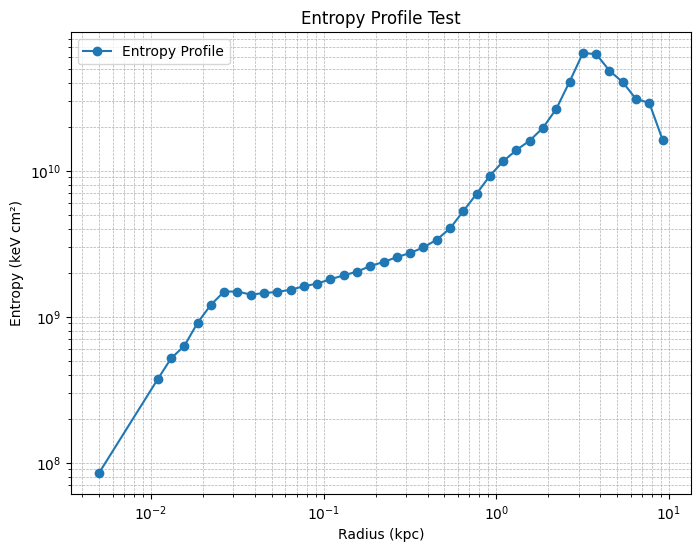

In [ ]:
import dill
import matplotlib.pyplot as plt
import numpy as np

# Load the profile from the .pkl file
with open("/home/b/babul/stlock/entropy_profiles/outputs/entropy_prof_L1_zoom_252_644_temp_cut=5e5K_nh_cut=0.13_cm-3.pkl", "rb") as f:
    profile = dill.load(f)

# Extract data
r = profile['x']['bin_centres']  # Radial bin centers
entropy = profile['y']['K_mass']  # Entropy

# Convert to log scale if necessary
log_r = np.log10(r)
log_entropy = np.log10(entropy)

# Plot
plt.figure(figsize=(8,6))
plt.plot(r, entropy, marker='o', linestyle='-', label="Entropy Profile")
plt.xscale("log")  # Log scale for radius
plt.yscale("log")  # Log scale for entropy (optional)
plt.xlabel("Radius (Mpc)")
plt.ylabel("Entropy (keV cm²)")
plt.title("Entropy Profile Test")
plt.legend()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.show()


In [ ]:
# ENTROPY IS WAY TOO LARGE
# RADIUS SHOULD GO TO ~100kpc

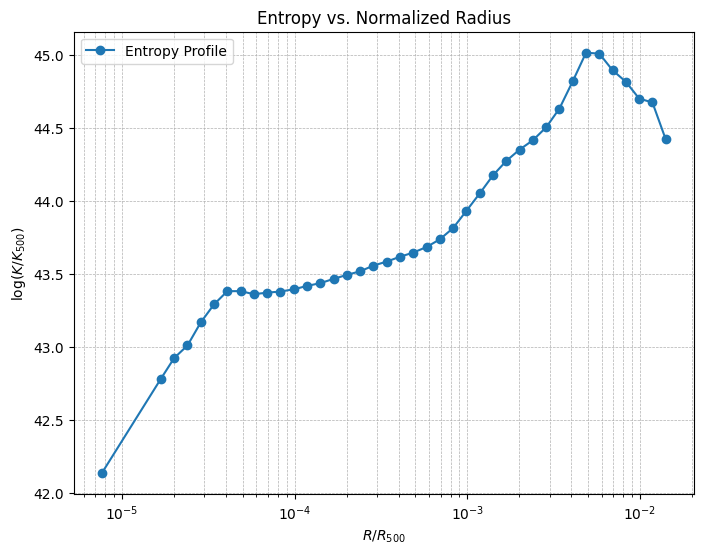

In [ ]:
import dill
import matplotlib.pyplot as plt
import numpy as np

# Load the profile from the .pkl file
with open("/home/b/babul/stlock/entropy_profiles/outputs/entropy_prof_L1_zoom_252_644_temp_cut=5e5K_nh_cut=0.13_cm-3.pkl", "rb") as f:
    profile = dill.load(f)

# Extract data
r = profile['x']['bin_centres']  # Radial bin centers
entropy = profile['y']['K_mass']  # Entropy

# Define R500 (you may need to set this manually or extract from the profile)
r500 = 652.3  # Example value, replace this with your actual R500 if available

# Normalize the radius
r_normalized = r / r500  # R / R500

# Compute K500 (entropy normalization constant)
mu = 0.59  # Mean molecular weight (adjust if needed)
mp = 1.67e-24  # Proton mass in g
keV_to_erg = 1.60218e-9  # Conversion factor from keV to erg
G = 6.67430e-8  # Gravitational constant in cgs
ne_over_nH = 1.17  # Electron-to-hydrogen number density ratio (assumed)

K500 = (keV_to_erg / ne_over_nH**(2/3)) * (G * mp * mu * r500 * (1e3))  # Convert r500 to cm

# Normalize entropy
entropy_normalized = entropy / K500

# Plot
plt.figure(figsize=(8,6))
plt.plot(r_normalized, np.log10(entropy_normalized), marker='o', linestyle='-', label="Entropy Profile")
plt.xscale("log")  # Log scale for R/R_500
plt.xlabel(r"$R / R_{500}$")
plt.ylabel(r"$\log (K / K_{500})$")
plt.title("Entropy vs. Normalized Radius")
plt.legend()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.show()
